# Ablación de las cabezas de la red funcional
Comparación de las cabezas lineal, MLP y KAN con los modelos entrenados en `funciones/Entrenamiento_red.py` (objetivo directo): mismo codificador, mismo decodificador FPCA, parámetros de KAN y MLP igualados (diferencia ≤ 10 %), 3 semillas por cabeza y el mismo presupuesto de entrenamiento. Las funciones están en `funciones/Ablacion_cabezas.py`.

Evaluación en validación: estaciones de validación en 1996–2000, que no están en entrenamiento. Las estaciones de prueba (2001–2003) no se usan.

## Configuración y datos

In [1]:
import sys
sys.path.append('funciones')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import Ablacion_arquitectura as Aa
import Ablacion_cabezas as Ac

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
D = Aa.preparar_datos()
print('Curvas de validación:', D['va'].sum(), '| estaciones:', D['meta'].STATION_ID[D['va']].nunique())
display(pd.read_csv('Tablas/08_red_configuracion_elegida.csv'))
pd.read_csv('Tablas/08_red_parametros_cabezas.csv')

Curvas de validación: 106 | estaciones: 25


,cabeza,q,M,lambda,mean,std
0,KAN,8,5,100.0,105.099440,10.851309
1,MLP,8,5,10000.0,80.824965,3.817611
2,lineal,8,5,1.0,109.111868,4.018065


,q,M,parametros_lineal,parametros_KAN,ocultas_MLP,parametros_MLP,diferencia_pct
0,6,5,45,442,31,439,0.678733
1,7,5,50,476,31,470,1.260504
2,8,5,55,510,32,517,1.372549


### Métricas
Todas las métricas se calculan frente a la curva suavizada de la estación (en mm, recortada en 0 como las predicciones). El satélite sin corregir es su curva suavizada.
- **L2_relativo**: $\|\hat y - y\| / \|y\|$ en la malla fina, promedio de las curvas.
- **KGE**: $1 - \sqrt{(r-1)^2 + (\alpha-1)^2 + (\beta-1)^2}$, mediana de las curvas.
- **sesgo_%**: sesgo del acumulado anual, diferencia porcentual entre el acumulado predicho y el de la curva de la estación.
- **pico1_pentadas / pico2_pentadas**: error en la fecha del máximo de marzo–junio y de septiembre–diciembre.
- **RECM_mm**: raíz del error cuadrático medio en las 72 péntadas.

Cada cabeza se resume con la media y la desviación estándar de sus 3 semillas.

In [2]:
predicciones = Ac.predicciones_validacion(D)
por_curva = Ac.tablas_por_curva(D, predicciones)
tabla_metricas = Ac.tabla_metricas(por_curva)
tabla_metricas.to_csv('Tablas/09_ablacion_cabezas_metricas.csv')
tabla_metricas.round(3)

,L2_relativo,L2_relativo_desv,KGE,KGE_desv,sesgo_%,sesgo_%_desv,pico1_pentadas,pico1_pentadas_desv,pico2_pentadas,pico2_pentadas_desv,RECM_mm,RECM_mm_desv
modelo,,,,,,,,,,,,
lineal,0.396,0.004,0.487,0.003,-9.442,3.077,3.938,0.139,1.677,0.104,14.350,0.511
MLP,0.376,0.007,0.504,0.010,-4.530,1.131,4.114,0.116,1.489,0.039,11.024,0.248
KAN,0.392,0.007,0.450,0.014,-8.261,3.878,4.578,0.088,1.584,0.117,13.629,1.144
Satélite sin corregir,0.493,NaN,0.391,NaN,-1.121,NaN,4.566,NaN,5.834,NaN,15.345,NaN


## Media y sesgo por péntada

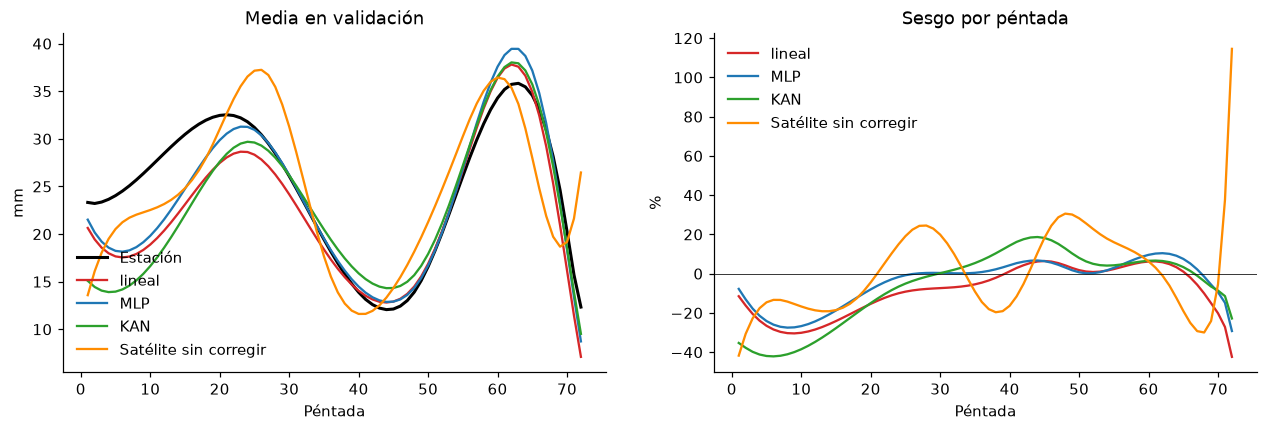

In [3]:
fig = Ac.grafica_media(D, predicciones); fig.savefig('Figuras/09_ablacion_cabezas_media_sesgo.png', dpi=150, bbox_inches='tight'); plt.show()

## ¿La red aprende más que la climatología?
Se compara cada modelo con la climatología de entrenamiento $\mu(t)$ (curva media de las estaciones de 1981–1995), que es lo que devolvería una red que solo aprende la media.
- **mejora_%**: reducción del error cuadrático frente a predecir $\mu(t)$ en todas las curvas.
- **curvas_mejores_%**: curvas de validación con menor RECM que $\mu(t)$.
- **corr_anomalias**: correlación entre $\hat y - \mu$ y $y - \mu$; si la red solo devuelve la media, es 0.
- **razon_desv_anomalias**: desviación de las anomalías predichas sobre la de las observadas; menor que 1 indica predicciones encogidas hacia la media.
- **corr_acumulado**: correlación entre acumulados anuales predichos y observados (distinguir años y sitios húmedos de secos).

Cada cabeza es el promedio de sus 3 semillas.

In [4]:
tabla_media = Ac.aprendizaje_media(D, predicciones)
tabla_media.to_csv('Tablas/09_ablacion_cabezas_climatologia.csv')
tabla_media.round(3)

,RECM_mm,mejora_%,curvas_mejores_%,corr_anomalias,razon_desv_anomalias,corr_acumulado
modelo,,,,,,
lineal,14.263,37.423,71.698,0.657,0.450,0.764
MLP,10.637,65.197,82.075,0.810,0.772,0.902
KAN,12.226,54.021,66.038,0.743,0.726,0.906
Satélite sin corregir,15.345,27.571,46.226,0.527,0.595,0.685
Climatología,18.030,0.000,0.000,NaN,NaN,NaN


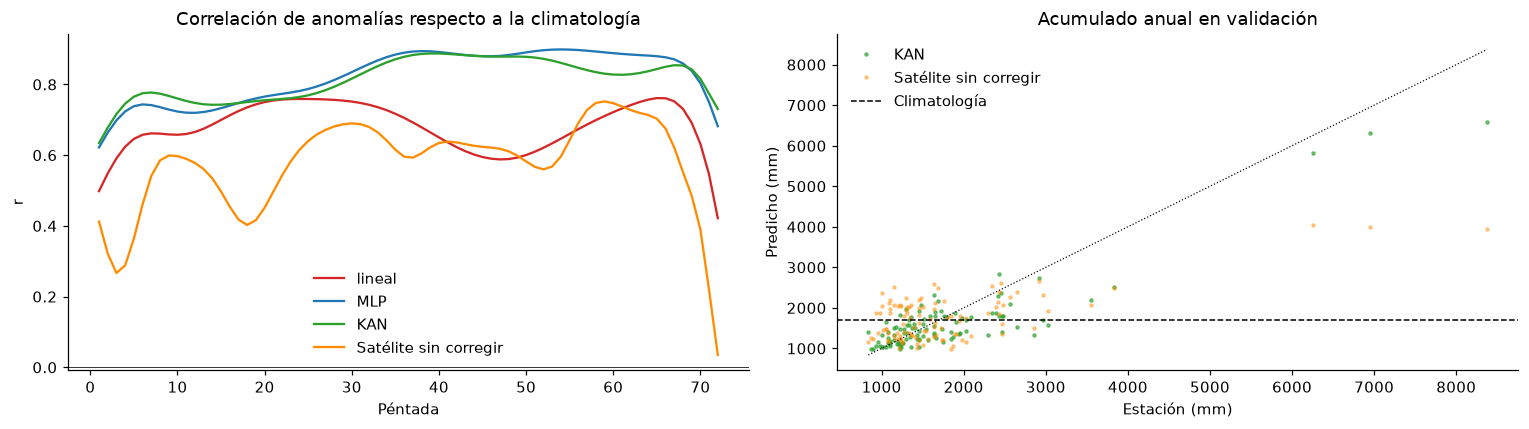

In [5]:
fig = Ac.grafica_anomalias(D, predicciones); fig.savefig('Figuras/09_ablacion_cabezas_anomalias.png', dpi=150, bbox_inches='tight'); plt.show()

## Desfase y fecha de los picos
Para cada curva se busca el rezago, entre −6 y +6 péntadas, con la mayor correlación entre la curva predicha y la de la estación (rezago > 0: la predicción va adelantada). Se reporta también el error con signo en la fecha de cada pico (> 0: el pico predicho llega tarde) además del error absoluto de la tabla de métricas.

In [6]:
tabla_rezagos, rezagos_por_curva = Ac.rezagos(D, predicciones)
tabla_rezagos.to_csv('Tablas/09_ablacion_cabezas_rezagos.csv')
tabla_rezagos.round(2)

,rezago_mediano,rezago_medio,curvas_rezago_0_%,curvas_rezago_hasta_1_%,rezago_curva_media,pico1_sesgo_pentadas,pico1_pentadas,pico2_sesgo_pentadas,pico2_pentadas
modelo,,,,,,,,,
lineal,0.0,0.48,24.53,54.72,0,2.63,3.91,-0.81,1.66
MLP,0.0,0.08,22.64,64.15,0,2.92,4.12,-0.58,1.47
KAN,0.0,0.05,17.92,68.87,0,3.65,4.48,-0.73,1.53
Satélite sin corregir,2.0,1.32,5.66,32.08,1,3.75,4.57,0.15,5.83
Climatología,0.0,-0.10,17.92,64.15,0,3.78,4.77,-0.40,1.52


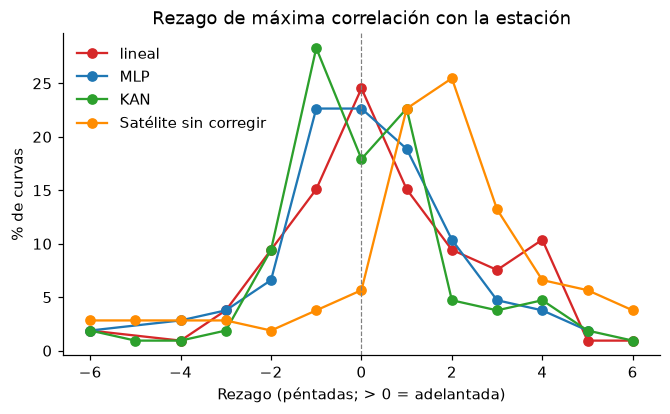

In [7]:
fig = Ac.grafica_rezagos(rezagos_por_curva); fig.savefig('Figuras/09_ablacion_cabezas_rezagos.png', dpi=150, bbox_inches='tight'); plt.show()

## Bootstrap por estaciones
Se remuestrean las estaciones de validación con reemplazo (2000 remuestreos) y cada estación aporta todas sus curvas. En cada remuestreo se calcula la métrica de cada cabeza (promedio de sus 3 semillas) y la diferencia entre cabezas. El IC del 95 % es el intervalo entre los percentiles 2,5 y 97,5 de las diferencias.

Una cabeza supera a otra solo si el IC del 95 % de la diferencia excluye el cero. En el sesgo se compara el valor absoluto.

In [8]:
remuestreos = Ac.bootstrap(D, por_curva)
comparacion = Ac.comparar(por_curva, remuestreos)
comparacion.to_csv('Tablas/09_ablacion_cabezas_bootstrap.csv', index=False)
comparacion.round(3)

,A,B,metrica,diferencia_A_menos_B,IC95_inferior,IC95_superior,conclusion
0,MLP,lineal,L2_relativo,-0.020,-0.050,0.009,Sin diferencia
1,MLP,lineal,KGE,0.017,-0.025,0.073,Sin diferencia
2,MLP,lineal,sesgo_abs_%,-4.912,-15.377,2.647,Sin diferencia
3,MLP,lineal,pico1_pentadas,0.176,-0.119,0.499,Sin diferencia
4,MLP,lineal,pico2_pentadas,-0.189,-0.273,-0.107,MLP supera a lineal
5,MLP,lineal,RECM_mm,-3.326,-7.901,0.008,Sin diferencia
6,KAN,lineal,L2_relativo,-0.004,-0.030,0.019,Sin diferencia
7,KAN,lineal,KGE,-0.037,-0.101,0.020,Sin diferencia
8,KAN,lineal,sesgo_abs_%,-1.181,-10.280,5.452,Sin diferencia
9,KAN,lineal,pico1_pentadas,0.640,0.151,1.200,lineal supera a KAN


In [9]:
comparacion.pivot_table(index=['A', 'B'], columns='metrica', values='conclusion', aggfunc='first')[list(Ac.METRICAS)]

metrica                                                 L2_relativo  \
A      B                                                              
KAN    MLP                                           Sin diferencia   
       Satélite sin corregir     KAN supera a Satélite sin corregir   
       lineal                                        Sin diferencia   
MLP    Satélite sin corregir     MLP supera a Satélite sin corregir   
       lineal                                        Sin diferencia   
lineal Satélite sin corregir  lineal supera a Satélite sin corregir   

metrica                                                         KGE  \
A      B                                                              
KAN    MLP                                           Sin diferencia   
       Satélite sin corregir                         Sin diferencia   
       lineal                                        Sin diferencia   
MLP    Satélite sin corregir     MLP supera a Satélite sin corregir   
       lineal                                        Sin diferencia   
lineal Satélite sin corregir  lineal supera a Satélite sin corregir   

metrica                          sesgo_abs_%  \
A      B                                       
KAN    MLP                    Sin diferencia   
       Satélite sin corregir  Sin diferencia   
       lineal                 Sin diferencia   
MLP    Satélite sin corregir  Sin diferencia   
       lineal                 Sin diferencia   
lineal Satélite sin corregir  Sin diferencia   

metrica                                              pico1_pentadas  \
A      B                                                              
KAN    MLP                                         MLP supera a KAN   
       Satélite sin corregir                         Sin diferencia   
       lineal                                   lineal supera a KAN   
MLP    Satélite sin corregir                         Sin diferencia   
       lineal                                        Sin diferencia   
lineal Satélite sin corregir  lineal supera a Satélite sin corregir   

metrica                                              pico2_pentadas  \
A      B                                                              
KAN    MLP                                           Sin diferencia   
       Satélite sin corregir     KAN supera a Satélite sin corregir   
       lineal                                        Sin diferencia   
MLP    Satélite sin corregir     MLP supera a Satélite sin corregir   
       lineal                                   MLP supera a lineal   
lineal Satélite sin corregir  lineal supera a Satélite sin corregir   

metrica                                                  RECM_mm  
A      B                                                          
KAN    MLP                                      MLP supera a KAN  
       Satélite sin corregir                      Sin diferencia  
       lineal                                     Sin diferencia  
MLP    Satélite sin corregir  MLP supera a Satélite sin corregir  
       lineal                                     Sin diferencia  
lineal Satélite sin corregir                      Sin diferencia

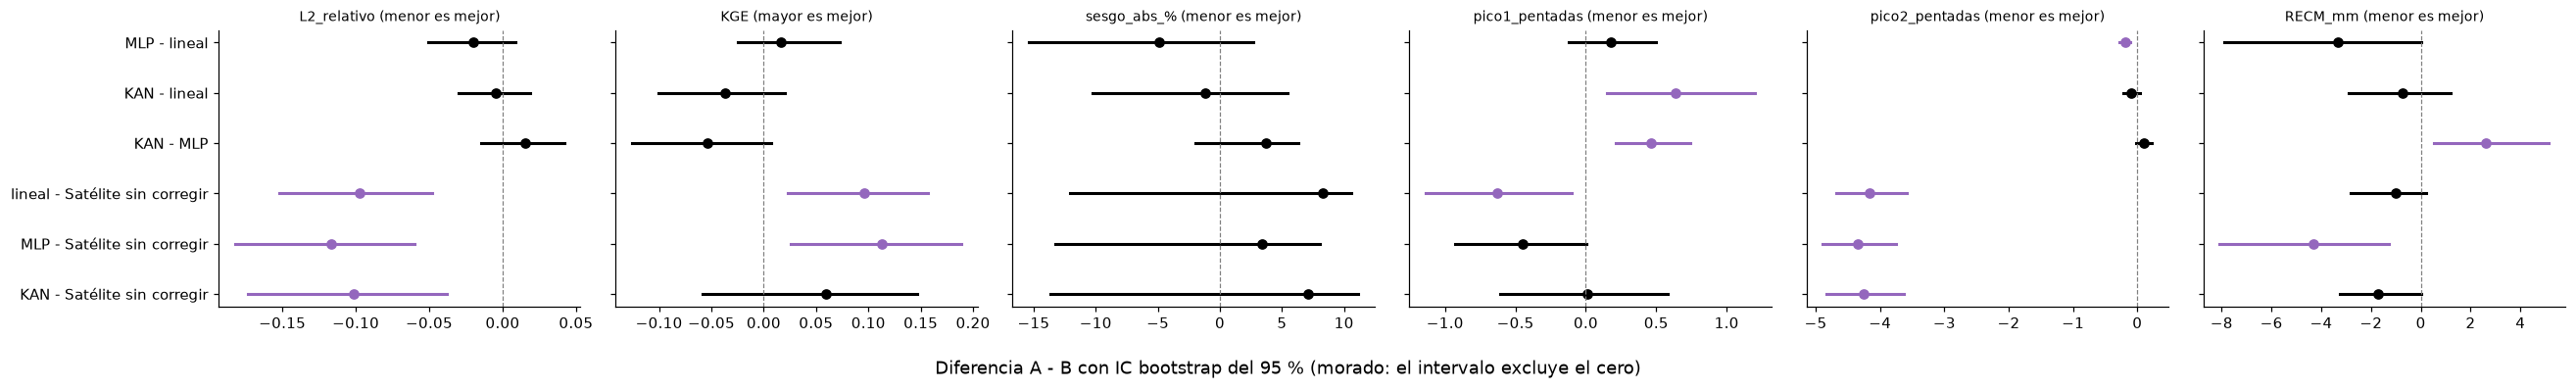

In [10]:
fig = Ac.grafica_intervalos(comparacion); fig.savefig('Figuras/09_ablacion_cabezas_bootstrap.png', dpi=150, bbox_inches='tight'); plt.show()